# Step 1: Setup and Original Data  
**Goal**: Load the 2D dataset we'll use for PCA.

Our dataset has 10 samples and 2 features (e.g., measurements like height and weight). We'll reduce it from 2D to 1D using PCA while preserving as much variance as possible.

$$
X = \begin{bmatrix}
2.5 & 2.4 \\
0.5 & 0.7 \\
2.2 & 2.9 \\
1.9 & 2.2 \\
3.1 & 3.0 \\
2.3 & 2.7 \\
2.0 & 1.6 \\
1.0 & 1.1 \\
1.5 & 1.6 \\
1.1 & 0.9 \\
\end{bmatrix}
$$

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Original dataset (10 samples, 2 features)
X = np.array([
    [2.5, 2.4],
    [0.5, 0.7],
    [2.2, 2.9],
    [1.9, 2.2],
    [3.1, 3.0],
    [2.3, 2.7],
    [2.0, 1.6],
    [1.0, 1.1],
    [1.5, 1.6],
    [1.1, 0.9]
])

print("Original Data (10 samples × 2 features):")
print(X)

Original Data (10 samples × 2 features):
[[2.5 2.4]
 [0.5 0.7]
 [2.2 2.9]
 [1.9 2.2]
 [3.1 3. ]
 [2.3 2.7]
 [2.  1.6]
 [1.  1.1]
 [1.5 1.6]
 [1.1 0.9]]


# Step 2: Mean Centering  
**Why?** PCA is sensitive to the mean of the data. We must center the data so that its mean is at the origin (0,0). This ensures the first principal component describes the direction of maximum variance *through the center of the data*.

We compute the mean of each feature (column) and subtract it from every sample:
$$
X_{\text{centered}} = X - \mu, \quad \text{where} \quad \mu = \begin{bmatrix} \bar{x}_1 & \bar{x}_2 \end{bmatrix}
$$

In [ ]:
# Compute mean of each feature (column-wise)
mean_vec = np.mean(X, axis=0)
print(f"Mean vector: [{mean_vec[0]:.2f}, {mean_vec[1]:.2f}]")

# Center the data
X_centered = X - mean_vec
print("\nCentered Data:")
print(np.round(X_centered, 4))

Mean vector: [1.81, 1.91]

Centered Data:
[[ 0.69  0.49]
 [-1.31 -1.21]
 [ 0.39  0.99]
 [ 0.09  0.29]
 [ 1.29  1.09]
 [ 0.49  0.79]
 [ 0.19 -0.31]
 [-0.81 -0.81]
 [-0.31 -0.31]
 [-0.71 -1.01]]


# Step 3: Compute the Covariance Matrix  
**Why?** The covariance matrix captures how the features vary together. High covariance indicates features change in a related way.

For centered data $X_{\text{centered}}$ (shape $n \times p$), the covariance matrix is:
$$
\Sigma = \frac{1}{n-1} X_{\text{centered}}^T X_{\text{centered}}
$$
This results in a $p \times p$ symmetric matrix (here, $2 \times 2$). The diagonal entries are the variances of each feature, and the off-diagonals are the covariances.

In [ ]:
# Calculate covariance matrix (2x2)
cov_matrix = np.cov(X_centered.T)  # Note: np.cov expects features in rows

print("Covariance Matrix:")
print(np.round(cov_matrix, 4))

Covariance Matrix:
[[0.6166 0.6154]
 [0.6154 0.7166]]


# Step 4: Eigen Decomposition  
**Why?** The eigenvectors of the covariance matrix point in the directions of maximum variance in the data. The corresponding eigenvalues tell us *how much* variance is captured in each direction.

We solve:
$$
\Sigma v = \lambda v
$$
- **Eigenvectors** ($v$): Define the principal components (new axes).
- **Eigenvalues** ($\lambda$): Measure the amount of variance along each principal component.

We sort eigenvectors by descending eigenvalues to prioritize components that explain the most variance.

In [ ]:
# Compute eigenvalues and eigenvectors
eigenvals, eigenvecs = np.linalg.eigh(cov_matrix)

# Sort in descending order (largest eigenvalue first)
idx = np.argsort(eigenvals)[::-1]
eigenvals = eigenvals[idx]
eigenvecs = eigenvecs[:, idx]

print("Eigenvalues (variance explained):")
print(np.round(eigenvals, 4))
print("\nEigenvectors (principal components):")
print(np.round(eigenvecs, 4))

# Explained variance ratio
explained_var_ratio = eigenvals / np.sum(eigenvals)
print(f"\nExplained Variance Ratio: PC1 = {explained_var_ratio[0]:.1%}, PC2 = {explained_var_ratio[1]:.1%}")

Eigenvalues (variance explained):
[1.284  0.0491]

Eigenvectors (principal components):
[[ 0.6779 -0.7352]
 [ 0.7352  0.6779]]

Explained Variance Ratio: PC1 = 96.3%, PC2 = 3.7%


# Step 5: Project Data onto Principal Components  
**Why?** To reduce dimensionality, we project the original (centered) data onto the top $k$ eigenvectors (principal components).

For 1D reduction, we use only the first eigenvector $w_1$:
$$
X_{\text{pca}} = X_{\text{centered}} \cdot w_1
$$
The result is a set of scalar values (scores) representing each sample in the new 1D space.

In [ ]:
# Select first principal component (column vector)
W = eigenvecs[:, 0].reshape(-1, 1)  # Shape: (2, 1)

# Project data: (10x2) @ (2x1) → (10x1)
X_pca = X_centered @ W

print("1D Projection (Principal Component Scores):")
print(np.round(X_pca.flatten(), 4))

1D Projection (Principal Component Scores):
[ 0.828  -1.7776  0.9922  0.2742  1.6758  0.9129 -0.0991 -1.1446 -0.438
 -1.2238]


# Step 6: Visualization  
We compare:
- **Left**: Original 2D data points.
- **Right**: Projected 1D points (all lie on a single line, which is the first principal component).

This shows how PCA compresses the data into fewer dimensions while preserving the most important pattern (direction of greatest spread).

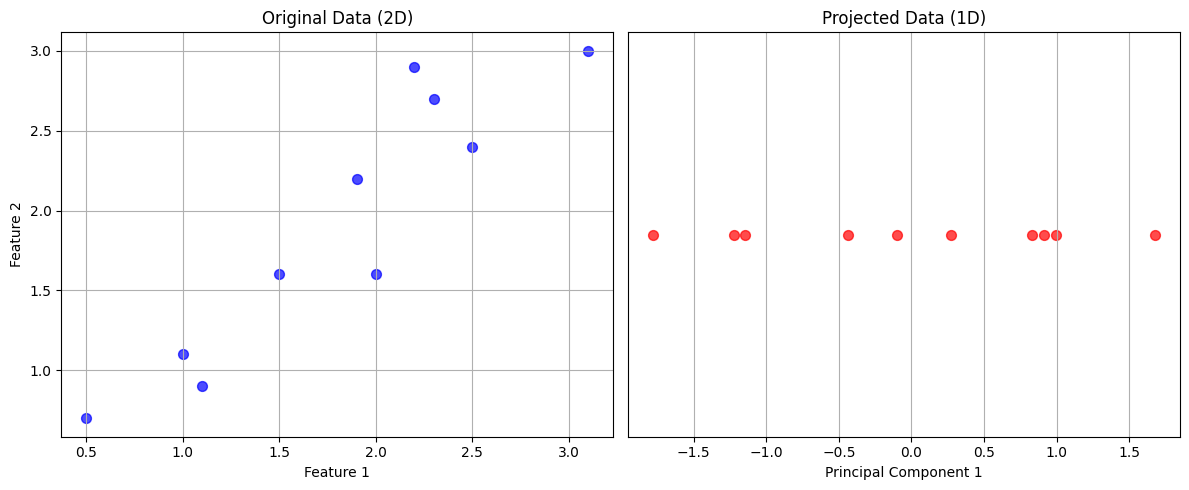

In [ ]:
# @title
plt.figure(figsize=(12, 5))

# Original data
plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], X[:, 1], c='blue', s=50, alpha=0.7)
plt.title('Original Data (2D)')
plt.xlabel('Feature 1'); plt.ylabel('Feature 2')
plt.grid(True)

# Projected data (1D)
plt.subplot(1, 2, 2)
plt.scatter(X_pca, np.zeros_like(X_pca), c='red', s=50, alpha=0.7)
plt.title('Projected Data (1D)')
plt.xlabel('Principal Component 1'); plt.yticks([])
plt.grid(True)

plt.tight_layout()
plt.show()

# Summary and Key Insights

- **Mean centering is critical**: PCA finds directions of variance *about the mean*.
- **Covariance matrix**: Encodes relationships between features.
- **Eigenvalues**: Quantify "importance" of each principal component. Here, PC1 explains over 96% of total variance!
- **Dimensionality reduction**: By keeping only top-$k$ components, we discard directions with low variance (often noise).

This step-by-step numerical example shows the core linear algebra behind PCA—no black boxes!